In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import time
import sys

np.set_printoptions(suppress=True)
np.set_printoptions(threshold=sys.maxsize)

In [2]:
permute3_3 = np.array([[0,1,2],
                     [0,2,1],
                     [1,0,2], 
                     [1,2,0], 
                     [2,0,1], 
                     [2,1,0]])

permute4_3 = np.array([[0,1,2],
                     [0,2,1],
                     [1,0,2], 
                     [1,2,0], 
                     [2,0,1], 
                     [2,1,0], 
                     [3,1,2],
                     [3,2,1],
                     [3,0,2], 
                     [3,2,0], 
                     [3,0,1], 
                     [3,1,0], 
                     [0,3,2],
                     [0,3,1],
                     [1,3,2], 
                     [1,3,0], 
                     [2,3,1], 
                     [2,3,0], 
                     [0,1,3],
                     [0,2,3],
                     [1,0,3], 
                     [1,2,3], 
                     [2,0,3], 
                     [2,1,3]])

permute5_3 = np.array([[0,1,2],
                     [0,2,1],
                     [1,0,2],
                     [1,2,0],
                     [2,0,1],
                     [2,1,0],
                     [3,1,2],
                     [3,2,1],
                     [3,0,2],
                     [3,2,0],
                     [3,0,1],
                     [3,1,0],
                     [0,3,2],
                     [0,3,1],
                     [1,3,2],
                     [1,3,0],
                     [2,3,1],
                     [2,3,0],
                     [0,1,3],
                     [0,2,3],
                     [1,0,3],
                     [1,2,3],
                     [2,0,3],
                     [2,1,3],
                     [4,1,2],
                     [4,2,1],
                     [4,0,2],
                     [4,2,0],
                     [4,0,1],
                     [4,1,0],
                     [0,4,2],
                     [0,4,1],
                     [1,4,2],
                     [1,4,0],
                     [2,4,1],
                     [2,4,0],
                     [0,1,4],
                     [0,2,4],
                     [1,0,4],
                     [1,2,4],
                     [2,0,4],
                     [2,1,4],
                     [4,1,3],
                     [4,2,3],
                     [4,0,3],
                     [4,3,0],
                     [4,3,1],
                     [4,3,2],
                     [0,4,3],
                     [1,4,3],
                     [2,4,3],
                     [3,4,0],
                     [3,4,1],
                     [3,4,2],
                     [0,3,4],
                     [1,3,4],
                     [2,3,4],
                     [3,0,4],
                     [3,1,4],
                     [3,2,4]])

permute5_2 = np.array([[0,1],
                      [0,2],
                      [0,3],
                      [0,4],
                      [1,0],
                      [1,2],
                      [1,3],
                      [1,4],
                      [2,0],
                      [2,1],
                      [2,3],
                      [2,4],
                      [3,0],
                      [3,1],
                      [3,2],
                      [3,4],
                      [4,0],
                      [4,1],
                      [4,2],
                      [4,3]])

permute4_2 = np.array([[0,1],
                       [0,2],
                       [0,3],
                       [1,0],
                       [1,2],
                       [1,3],
                       [2,0],
                       [2,1],
                       [2,3],
                       [3,0],
                       [3,1],
                       [3,2]])

permute3_2 = np.array([[0,1],
                       [0,2],
                       [1,0],
                       [1,2],
                       [2,0],
                       [2,1]])

In [6]:
# Signal and system parameters

D = 11 # distance of the UE from the gNB (in m)
c = 3e8
f_c = 3.6192e9
bandwidth = 20e6
N_cp = 72
scs = 30e3
K_TC = 8 # SRS Comb size

if bandwidth == 20e6:
    f_s = 30.72e6
    N_ifft = 1024
    nPRB = 51
    occ_bandwidth = 12*nPRB*scs
    
elif bandwidth == 40e6:
    f_s = 61.44e6
    N_ifft = 2048
    nPRB = 106
    occ_bandwidth = 12*nPRB*scs

osf = 8
N_ant = 4
d_ant = 1/2*np.arange(0, N_ant, 1) # inter-element distance (in terms of wavelength)
P_t = 0.1 # Watt
K = 1.380649e-23
T = 298
noise_var = K*bandwidth*T

In [ ]:
# # Channel parameters

# K = 10
# Dist = 13 # Distance of UE from gNB in meters
# tau = 1/c*np.transpose(np.array([np.zeros(K), 20*np.random.rand(K)+9, 30*np.random.rand(K)+9])) # Transmit delay in s (converted from meters)
# theta = np.pi/180*np.transpose(np.array([np.zeros(K), -60*np.random.rand(K)-10, 60*np.random.rand(K)+10])) # AoA in radians (converted from degrees)
# Doppler = np.zeros([K, 3]) # Doppler in Hz (converted from m/s)
# free_space = P_t*(c/f_c*1/(4*np.pi*Dist))**2
# free_space = free_space/noise_var
# pathgain = free_space*np.array([1, 0.2, 0.07])

In [15]:
# Channel parameters

chan_params = np.load('/home/bkumar2/Documents/Research/ISAC-twin/Simulation_framework/Datasets/Indoor_scenario/Trajectory_1/ISAC_ray_tracing_chan.npy')

K = 100
tau = chan_params[:, 2, :] # Transmit delay in s 
theta = chan_params[:, 0, :] # AoA in radians
Doppler = chan_params[:, 1, :] # Doppler in Hz (converted from m/s)
pathgain = chan_params[:, 3, :] # Pathgain in absolute value

for k in range(0, K):
    order = np.argsort(pathgain[k, :])[::-1]
    tau[k, :] = tau[k, order]
    theta[k, :] = theta[k, order]
    Doppler[k, :] = Doppler[k, order]
    pathgain[k, :] = pathgain[k, order]

# Repeat the same values K times for averaging (Monte carlo simulation)
# tau = np.tile(np.reshape(tau, [1, len(tau)]), [K, 1])
# theta = np.tile(np.reshape(theta, [1, len(theta)]), [K, 1])
theta = theta + np.pi
theta = np.pi/2 - theta
theta = (theta + np.pi) % (2 * np.pi) - np.pi
# Doppler = np.tile(np.reshape(Doppler, [1, len(Doppler)]), [K, 1])
pathgain = P_t*pathgain/noise_var

In [17]:
idx = 30
print(pathgain[idx, :])
print(theta[idx, :]*180/np.pi)
print(tau[idx, :]*1e9)

[466627.72255199  61145.71815245  43843.02391641  14703.65780194
   9619.24915765   9619.07753769   1410.98808008    683.68764622
    616.34286721    616.34151799    369.8291764     113.87527464
     14.7704097      11.92822711     11.51051903      1.17852326
      1.17838412      0.              0.              0.
      0.              0.              0.              0.
      0.        ]
[   0.0000025     0.0000025     2.29657848    0.0000025     0.0000025
    0.0000025  -164.3862447     0.0000025     6.902619     -6.90261399
    0.0000025     0.0000025     2.15106813 -170.17214576   -7.40644973
  141.57514956 -141.57512384  -90.          -90.          -90.
  -90.          -90.          -90.          -90.          -90.        ]
[ 36.69205029  37.26728792  52.67728653  63.0304271   46.69813336
  46.69813336  81.43297237  50.99102651  49.67253275  49.67253275
  37.29359577  46.79024102 103.17806698  67.01459654 106.93750596
  57.21059892  57.21059182   0.           0.           0.
   0.

In [18]:
# Compute the CDF from data and x values (x values are the values at which we want to evaluate the CDF)
def cdf(err, x):
    CDF = np.zeros(len(x))
    for iter in range(0, len(x)):
        CDF[iter] = np.sum(err <= x[iter])/len(err)
    return CDF


### Function to estimate the position of the object of interest from the estimated range, angle of the reflected path and distance of the UE from the gNB
def est_pos(d, l_hat, theta_hat):
    x1 = (d + l_hat)*np.sin(theta_hat)
    y1 = (d + l_hat)*np.cos(theta_hat)
    m = (y1 - d)/x1

    x_mid = x1/2
    y_mid = (y1 + d)/2

    x_s_hat = (x_mid/m + y_mid)/(1/m + 1/np.tan(theta_hat))
    y_s_hat = x_s_hat/np.tan(theta_hat)

    return x_s_hat, y_s_hat


# Function to estimate the full channel estimates from combed channel estimates using interpolation (Support only for K_TC = 2 for now)
def interpolate_channel_estimates(H_combed, nPRB, N_ifft, K_TC):
    H_combed = np.concatenate([H_combed[N_ifft-6*nPRB:N_ifft], H_combed[0:6*nPRB]])
    K_srs = int(np.ceil(12*nPRB / K_TC))
    H = np.zeros([12*nPRB], dtype=np.complex128)
    n = 0

    if K_TC == 2:
        filt8_start = np.array([12288, 8192, 4096, 0, 0, 0, 0, 0])/16384
        filt8_end = np.array([4096, 8192, 12288, 16384])/16384
        filt8_middle2 = np.array([4096, 8192, 8192, 8192, 4096, 0, 0, 0])/16384
        filt8_middle4 = np.array([0, 0, 4096, 8192, 8192, 8192, 4096, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt8_start)] = H[n:n+len(filt8_start)] + H_combed[k*K_TC]*filt8_start
            elif k == K_srs-1:
                H[n:n+len(filt8_end)] = H[n:n+len(filt8_end)] + H_combed[k*K_TC]*filt8_end
            elif np.mod(k, 2) == 1:
                H[n:n+len(filt8_middle2)] = H[n:n+len(filt8_middle2)] + H_combed[k*K_TC]*filt8_middle2
            elif np.mod(k, 2) == 0:
                H[n:n+len(filt8_middle4)] = H[n:n+len(filt8_middle4)] + H_combed[k*K_TC]*filt8_middle4
                n = k*K_TC

    elif K_TC == 4:
        filt16_start = np.array([12288, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 0, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + H_combed[k*K_TC]*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + H_combed[k*K_TC]*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + H_combed[k*K_TC]*filt16_middle
                n = k*K_TC

    elif K_TC == 8:
        filt16_start = np.array([12288, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096, 0, 0, 0, 0, 0, 0, 0])/16384
        filt16_end = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 12288, 16384, 16384, 16384, 16384, 16384, 16384, 16384])/16384
        filt16_middle = np.array([4096, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 8192, 4096])/16384

        for k in range(0, K_srs):
            if k == 0:
                H[n:n+len(filt16_start)] = H[n:n+len(filt16_start)] + H_combed[k*K_TC]*filt16_start
            elif k == K_srs-1:
                if n+len(filt16_end) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_end[0:len(H)-n]
                else:
                    H[n:n+len(filt16_end)] = H[n:n+len(filt16_end)] + H_combed[k*K_TC]*filt16_end
            else:
                if n+len(filt16_middle) > len(H):
                    H[n:len(H)] = H[n:len(H)] + H_combed[k*K_TC]*filt16_middle[0:len(H)-n]
                else:
                    H[n:n+len(filt16_middle)] = H[n:n+len(filt16_middle)] + H_combed[k*K_TC]*filt16_middle
                n = k*K_TC
            

    H = np.concatenate([H[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), H[0:6*nPRB]])
    
    return H


# Function to find LoS path using the estimated AoA and ToF
def find_los(t_est, theta_est, alpha_est, aoa_ue):
    alpha_max = np.max(np.abs(alpha_est))
    
    while(len(t_est) > 0): # Continue until there is a path left to process
        l_ue = np.argmin(t_est) # Find the path index with the minimum transmit delay
        if (np.abs(theta_est[l_ue] - aoa_ue) > 7.5) or (np.abs(alpha_est[l_ue]) < 0.5*alpha_max): # Ignore the path if it is not coming from the UE or if it is too weak. LoS from the UE should be one of the strongest paths if not the strongest.
            t_est = np.delete(t_est, l_ue)
            theta_est = np.delete(theta_est, l_ue)
            alpha_est = np.delete(alpha_est, l_ue)
        else:
            break

    return t_est, theta_est, alpha_est, l_ue

In [20]:
# Generate the received signal

# No. of paths
L = np.shape(tau)[1]

# Generated signal for K scenarios, N_ant antennas and N_ifft samples
gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)

# Transmitted OFDM symbols
# Xn = np.random.randint(0, 4, [12*nPRB]) # QPSK symbols
# Xn = np.exp(1j*(np.pi*Xn/2 + np.pi/4))

Xn = np.zeros([12*nPRB], dtype=np.complex128)
m = np.arange(0, int(np.ceil(12*nPRB / K_TC)), 1)
Xn[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m))) # SRS pilot symbols (ZC sequence)
Xn[np.setdiff1d(np.arange(0, 12*nPRB, 1), np.arange(0, 12*nPRB, K_TC))] = np.exp(1j*(np.pi*np.random.randint(0, 4, [12*nPRB - len(m)])/2 + np.pi/4)) # Remaining subcarriers transmit QPSK symbols
Xn = np.concatenate([Xn[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[0:6*nPRB]])
Xn = np.reshape(Xn, [N_ifft, 1])

X_pilot = np.zeros([12*nPRB], dtype=np.complex128)
X_pilot[np.arange(0, 12*nPRB, K_TC)] = np.exp(-1j*np.pi*m*(m + 2)/(len(m)))
X_pilot = np.concatenate([X_pilot[6*nPRB:12*nPRB], np.zeros(N_ifft - 12*nPRB), X_pilot[0:6*nPRB]])

t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
n = np.reshape(n, [N_ifft, 1])
n = np.tile(n, [1, N_ifft])

# This loop just generates the OFDM samples in time domain
for k in range(0, K):
    for l in range(0, L):
        if (theta[k, l] >= -np.pi/2) and (theta[k, l] < np.pi/2):
            phase = np.exp(1j*2*np.pi*np.random.rand())
            temp_sgnl = 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[k, l]) * phase * \
                        np.exp(1j*2*np.pi*Doppler[k, l]*t) * \
                        np.sum(np.tile(Xn, [1, N_ifft])*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[k, l], [1, N_ifft]), [N_ifft, 1])), axis=0)

            gen_signal[k, :, :] = gen_signal[k, :, :] + np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(theta[k, l])), [N_ant, 1]), [1, N_ifft]) * \
                                                        np.tile(np.reshape(temp_sgnl, [1, N_ifft]), [N_ant, 1])

# Add the AWGN noise to the generated samples
rcvd_signal = gen_signal #+ np.random.normal(size=[K, N_ant, N_ifft])

# Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=2)

# Estimate the channel using X_pilot as pilot symbols
H_combed = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) 

for i in range(0, N_ifft):
    if X_pilot[i] == 0:
        H_combed[:, :, i] = np.zeros([K, N_ant])
    else:
        H_combed[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(X_pilot[i], [K, N_ant]))

H_interpolated = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)
for k in range(0, K):
    for n_ant in range(0, N_ant):
        H_interpolated[k, n_ant, :] = interpolate_channel_estimates(H_combed[k, n_ant, :], nPRB, N_ifft, K_TC)

# Estimate the channel using Xn as pilot symbols
H_full = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) 

for i in range(0, N_ifft):
    if Xn[i] == 0:
        H_full[:, :, i] = np.zeros([K, N_ant])
    else:
        H_full[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(Xn[i, 0], [K, N_ant]))

In [25]:
# print(H_combed[0,0,:])

print(X_pilot)

[ 0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
 -0.74223412-0.67014066j  0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.84125353+0.54064082j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j         -0.94720301-0.32063446j  0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  1.        -0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j         -0.91791659+0.39677341j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.        +0.j          0.        +0.j          0.        +0.j
  0.     

In [7]:
np.sum(np.abs(H_full - H_interpolated))/np.sum(np.abs(H_full)) # Comb size = 2

np.float64(6.998374188791117e-05)

In [14]:
np.sum(np.abs(H_full - H_interpolated))/np.sum(np.abs(H_full)) # Comb size = 4

np.float64(0.003957997588927807)

In [21]:
np.sum(np.abs(H_full - H_interpolated))/np.sum(np.abs(H_full)) # Comb size = 8

np.float64(0.011568937178820633)

1.2227791303204544e-09


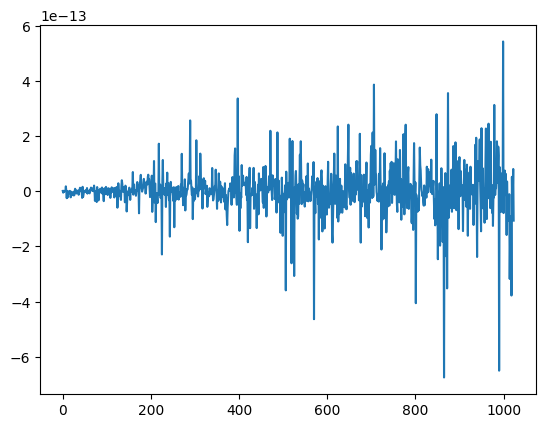

In [ ]:
# Ignore this part of the code. This was only done to check different methods of sample generation and if they lead to the same result or not as a proof of concept.

temp_tau = 8.77341851e-08
n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
n = np.reshape(n, [N_ifft, 1])
a0 = np.sum(np.tile(Xn, [1, N_ifft])*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-temp_tau, [1, N_ifft]), [N_ifft, 1])), axis=0)
a1 = Xn*np.exp(-1j*2*np.pi*n*scs*temp_tau)
a2 = N_ifft*np.fft.ifft(a1, axis=0)

phase = np.angle(a2[:, 0]*np.conjugate(a0))
plt.plot(phase)
print(np.sum(np.abs(a2[:,0]-a0)))

In [74]:
# Plotting the estimated channel in time domain (CIR)

%matplotlib qt
oversampled_H = np.concatenate([H[0, 0, 0:N_ifft//2], np.zeros((osf-1)*N_ifft), H[0, 0, N_ifft//2:N_ifft]])
cir = np.fft.ifft(oversampled_H)
plt_osf = 1
cir = np.concatenate([cir[-(plt_osf*N_ifft)//2:], cir[0:(plt_osf*N_ifft)//2]])

plt.semilogy(np.arange(-(plt_osf*N_ifft)//2, (plt_osf*N_ifft)//2, 1)/(8*f_s), np.abs(cir))
plt.xlabel("Time (us)", fontsize=30)
plt.ylabel("CIR", fontsize=30)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.show()

In [29]:
# Implementation of mD-Track algorithm
%matplotlib qt

L = 3 # No. of paths we are estimating
RMSE = np.zeros([2, L]) # RMSE for ToA and AoA for all the estimated paths

track_params = np.zeros([10, 5, 2])
track_idx = 0
n_paths = np.zeros(np.shape(track_params)[1])

# First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
complex_time0 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
complex_time1 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
complex_time2 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
complex_time3 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

# This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
time_gensym = np.sqrt(N_ifft)*np.fft.ifft(Xn_os)

# n_Dopp = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(0, N_ifft//2, 1)])

for iter0 in range(0, 70):
    est_mean_time0 = complex_time0[iter0, :]
    est_mean_time1 = complex_time1[iter0, :]
    est_mean_time2 = complex_time2[iter0, :]
    est_mean_time3 = complex_time3[iter0, :]

    mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

    resolve = 5 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
    parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

    # Search space for the parameters
    f_search = np.arange(-2000, 2000, 1000)
    t_search = np.arange(-50, 50, 1)
    theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)

    print("-------------------- Symbol no. {} --------------------".format(iter0))
    
    for iter in range(0, resolve):

        beam_strength = np.zeros([len(theta_search), L])
        caf_freq = np.zeros([len(f_search), L])
        caf_time = np.zeros([len(t_search), L])
        
        for l in range(0, L):

            # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
            if iter > 0:
                generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant,1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, osf*N_ifft])
                generated_sig = np.roll(generated_sig, int(np.real(parameters[2, l])), axis=1)
                generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                generated_sig = parameters[3, l]*generated_sig
                mean_chan_subcarrier = generated_sig + residual_sig

            if iter > 2:
                theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                f_search = np.arange(-200, 200, 100) + np.real(parameters[1, l])

            est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

            mean_chan = np.average(est_mean_rxsym, axis=1)

            # START - Code for beam sweeping here and finding the strongest direction.

            for i in range(0, len(theta_search)):
                beam_strength[i, l] = np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                
            # if iter == 0:
            #     plt.figure(2*L*iter + 2*l)
            #     plt.polar(theta_search, beam_strength[:, l])

            max_idx = np.argmax(beam_strength[:, l])
            max_theta = theta_search[max_idx] 

            parameters[0, l] = max_theta
            # END - Code for beam sweeping here and finding the strongest direction.

            time2 = time.time()

            # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

            n = np.arange(0, osf*N_ifft, 1)

            combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])*mean_chan_subcarrier, axis=0)

            max_caf = 0
            for t in range(0, len(t_search)):
                caf_time[t, l] = np.abs(np.sum(np.roll(np.conj(time_gensym), t_search[t])*combined_chan))
                if caf_time[t,l] > max_caf:
                    t_best = t
                    max_caf = caf_time[t,l]
                
            max_caf = 0
            shifted_combined_chan = np.roll(np.conj(time_gensym), t_search[t_best])*combined_chan
            for f in range(0, len(f_search)):
                caf_freq[f, l] = np.abs(np.sum(shifted_combined_chan*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))))
                if caf_freq[f,l] > max_caf:
                    f_best = f
                    max_caf = caf_freq[f,l]

            # idx = np.argmax(caf[:, :, l])
            # f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

            parameters[1, l] = f_search[f_best]
            parameters[2, l] = t_search[t_best]

            # END - Code for estimating the transmit delay and Doppler using CAF

            # if iter == resolve-1:
            #     plt.figure(2*L*iter + 2*l+1)
            #     plt.imshow(caf[:, :, l], cmap='hot', interpolation='nearest')
            #     plt.xlabel("Delay sweep")
            #     plt.ylabel("Doppler sweep")

            # START - Code that is used to regenerate the signal using the estimated parameters

            generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant,1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])

            generated_sig = np.roll(generated_sig, t_search[t_best], axis=1)

            generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

            alpha = np.average(mean_chan_subcarrier/generated_sig)

            parameters[3, l] = alpha

            generated_sig = alpha*generated_sig

            residual_sig = mean_chan_subcarrier - generated_sig

            mean_chan_subcarrier = residual_sig

            if iter == resolve-1:
                print("Path no. {} - estimated delay is {} ns and estimated AoA is {}°".format(l, t_search[t_best]/(osf*f_s)*1e9, 180/np.pi*max_theta))
                # print("Path no. {} - true delay is {} ns and true AoA is {}°".format(l, tau[iter0, l]*1e9, 180/np.pi*theta[iter0, l]))
                # print("Estimated Doppler is {} Hz".format(f_search[f_best]))
                # print("Estimated path gain is {}".format(alpha))

                # RMSE[0, l] = RMSE[0, l] + (tau[iter0, l]*1e9 - tau[iter0, 0]*1e9 - np.real(parameters[2,l])/(osf*f_s)*1e9 + np.real(parameters[2,0])/(osf*f_s)*1e9)**2
                # RMSE[1, l] = RMSE[1, l] + (180/np.pi*theta[iter0, l] - 180/np.pi*np.real(parameters[0,l]))**2

    # This part of the code will track the parameters - AoA and ToF
    if track_idx == 0: # First keep the first set of parameters in index 0 (l_idx indicates how many different sets of parameters are there in index 0)
        track_params[track_idx, 0:L, 0] = np.real(parameters[2, :])/(osf*f_s)*1e9
        track_params[track_idx, 0:L, 1] = 180/np.pi*np.real(parameters[0, :])
        n_paths[0:L] = n_paths[0:L] + 1
        l_idx = L

    else:
        t_est = np.real(parameters[2, :])/(osf*f_s)*1e9
        theta_est = 180/np.pi*np.real(parameters[0, :])

        # This section of the code is used to find if the newly estimated parameters can be assigned to any of the existing paths (track_params) or a new path. 
        # We are using a simple threshold based method here for this assignment.
        l = 0
        while(l < len(t_est)):
            # if np.min(np.abs(track_params[0, 0:l_idx, 0] - np.tile(t_est[l], l_idx))) > 20 or np.min(np.abs(track_params[0, 0:l_idx, 1] - np.tile(theta_est[l], l_idx))) > 10:
            if np.min(np.abs(track_params[0, 0:l_idx, 0] - np.tile(t_est[l], l_idx)) + np.abs(track_params[0, 0:l_idx, 1] - np.tile(theta_est[l], l_idx))) > 25:
                if l_idx < 5:
                    track_params[0, l_idx, 0] = t_est[l]
                    track_params[0, l_idx, 1] = theta_est[l]
                    n_paths[l_idx] = n_paths[l_idx] + 1
                    l_idx = l_idx + 1
                    t_est = np.delete(t_est, l)
                    theta_est = np.delete(theta_est, l)
                    print("{}th path will be saved.".format(l))
                else:
                    print("More than 5 paths are there. Neglecting {}th path.".format(l))
                    t_est = np.delete(t_est, l)
                    theta_est = np.delete(theta_est, l)
                l = l - 1

            l = l + 1
                    
        
        # Why does greedy not work here? - Because when doing greedy we may assign an outlier path to a track_params index which should have been assigned to the next 
        # path. And we won't be able to assign the next path properly. 
        # We are implementing brute force method by searching through all possible permutations because the number of paths is very small (3 to 5). 
        # For larger number of paths, we can implement Hungarian algorithm or any other efficient algorithm for assignment problem.
        
        loss = np.abs(np.tile(np.reshape(t_est, [1, len(t_est)]), [l_idx, 1]) - np.tile(track_params[0, 0:l_idx, 0:1], [1, len(t_est)])) + \
               np.abs(np.tile(np.reshape(theta_est, [1, len(t_est)]), [l_idx, 1]) - np.tile(track_params[0, 0:l_idx, 1:2], [1, len(t_est)]))

        if (l_idx == 3) and (len(t_est) == 3):
            permute = permute3_3
        if (l_idx == 4) and (len(t_est) == 3):
            permute = permute4_3
        if (l_idx == 5) and (len(t_est) == 3):
            permute = permute5_3
        if (l_idx == 3) and (len(t_est) == 2):
            permute = permute3_2
        if (l_idx == 4) and (len(t_est) == 2):
            permute = permute4_2
        if (l_idx == 5) and (len(t_est) == 2):
            permute = permute5_2
        if len(t_est) == 1:
            permute = np.reshape(np.arange(0, l_idx, 1), [l_idx, 1])

        min_loss = 10000
        min_idx = -1

        for iter1 in range(0, np.shape(permute)[0]):
            if len(t_est) == 3:
                indices = ((permute[iter1, 0], permute[iter1, 1], permute[iter1, 2]), (0, 1, 2))
            if len(t_est) == 2:
                indices = ((permute[iter1, 0], permute[iter1, 1]), (0, 1))
            if len(t_est) == 1:
                indices = (permute[iter1], 0)
            
            permuted_loss = np.sum(loss[indices])
            
            if permuted_loss < min_loss:
                min_loss = permuted_loss
                min_idx = iter1
            
        asgnmnt = permute[min_idx, :]

        print(track_params[0, 0:l_idx, :])
        print(loss)

        for l in range(0, len(t_est)):
            track_params[track_idx, asgnmnt[l], 0] = t_est[l]
            track_params[track_idx, asgnmnt[l], 1] = theta_est[l]
            n_paths[asgnmnt[l]] = n_paths[asgnmnt[l]] + 1

        print(asgnmnt)
        print(n_paths)
        print("========================")
    
    track_idx = track_idx + 1

    if track_idx == 10:
        est_mean_delay = np.sum(track_params[:, 0:l_idx, 0], axis=0)/n_paths[0:l_idx]
        est_mean_aoa = np.sum(track_params[:, 0:l_idx, 1], axis=0)/n_paths[0:l_idx]
        corr_paths = [i for i in range(0, len(n_paths)) if n_paths[i] > 4]
        
        # Reinitialize the variables for next 10 iterations of tracking
        track_params = np.zeros([10, 5, 2])
        track_idx = 0
        n_paths = np.zeros(np.shape(track_params)[1])

        plt.figure((iter0+1) // 10)
        plt.scatter(est_mean_aoa[corr_paths], est_mean_delay[corr_paths], c='b', marker='o', linewidth=10)
        plt.xlabel("AoA (degrees)", fontsize=30)
        plt.ylabel("Transmit delay (ns)", fontsize=30)
        plt.grid(True)
        plt.xticks(fontsize=30)
        plt.yticks(fontsize=30)

            # if iter == resolve-1 and l == L-1:
            #     plt.figure(iter0)
            #     plt.scatter(180/np.pi*np.real(parameters[0, :]), np.real(parameters[2, :])/(osf*f_s)*1e9, c='b', marker='o', linewidth=10)
            #     plt.xlabel("AoA (degrees)", fontsize=30)
            #     plt.ylabel("Transmit delay (ns)", fontsize=30)
            #     plt.grid(True)
            #     plt.xticks(fontsize=30)
            #     plt.yticks(fontsize=30)

        # END - Code that is used to regenerate the signal using the estimated parameters

RMSE = np.sqrt(RMSE/(K))

time3 = time.time()
# print("The timestamps for the program are = {}, {}, {}, {}".format(time0, time1, time2, time3))
# print(parameters)
plt.show()

-------------------- Symbol no. 0 --------------------
Path no. 0 - estimated delay is 44.759114583333336 ns and estimated AoA is -0.6185839595915188°
Path no. 1 - estimated delay is 16.276041666666668 ns and estimated AoA is -0.6185839595915188°
Path no. 2 - estimated delay is 44.759114583333336 ns and estimated AoA is -10.358866476815525°
-------------------- Symbol no. 1 --------------------
Path no. 0 - estimated delay is 40.690104166666664 ns and estimated AoA is -0.6185839595915188°
Path no. 1 - estimated delay is 12.20703125 ns and estimated AoA is 0.5273316306701255°
Path no. 2 - estimated delay is 48.828125 ns and estimated AoA is -13.796613247600472°
[[ 44.75911458  -0.61858396]
 [ 16.27604167  -0.61858396]
 [ 44.75911458 -10.35886648]]
[[ 4.06901042 33.69799892 17.2470397 ]
 [24.4140625   5.21492601 45.73011262]
 [13.80929293 43.43828144  7.50675719]]
[0 1 2]
[2. 2. 2. 0. 0.]
-------------------- Symbol no. 2 --------------------
Path no. 0 - estimated delay is 40.6901041666

In [30]:
n_paths = np.array([10, 10,  2,  8,  0])
a = [i for i in range(0, len(n_paths)) if n_paths[i] > 4]

print(n_paths)
print(a)

[10 10  2  8  0]
[0, 1, 3]


In [34]:
# print(track_params)
# print(n_paths)
print(est_mean_delay)
print(est_mean_aoa)

[ 35.80729167  99.69075521  78.125      618.48958333 345.86588542]
[ 5.34017711 11.25888375 41.26463086  9.948231    0.29920081]


In [14]:
print(180/np.pi*theta[1, :])
print(1e9*tau[1, :])
print(np.sqrt(pathgain[1, :]))
print("---------------------")
print(180/np.pi*theta[11, :])
print(1e9*tau[11, :])
print(np.sqrt(pathgain[11, :]))
print("---------------------")
print(180/np.pi*theta[21, :])
print(1e9*tau[21, :])
print(np.sqrt(pathgain[21, :]))
print("---------------------")
print(180/np.pi*theta[32, :])
print(1e9*tau[32, :])
print(np.sqrt(pathgain[32, :]))
print("---------------------")
print(180/np.pi*theta[41, :])
print(1e9*tau[41, :])
print(np.sqrt(pathgain[41, :]))
print("---------------------")
print(180/np.pi*theta[50, :])
print(1e9*tau[50, :])
print(np.sqrt(pathgain[50, :]))


[   0.0000025     0.0000025     0.0000025   162.78945758 -157.04091584
    2.29657848    0.0000025     0.0000025     0.0000025     0.0000025
    6.902619     -6.90261399    0.0000025     0.0000025     2.15106813
 -170.17214576   -7.40644973    7.4064479   141.57514956 -141.57512384
  -90.          -90.          -90.          -90.          -90.        ]
[ 36.69205029  42.97015366  37.26728792  44.9447235   45.12895302
  52.67728653  63.0304271   46.69813336  46.69813336  50.99102651
  49.67253275  49.67253275  37.29359577  46.79024102 103.17806698
  67.01459654 106.93750596 106.93752017  57.21059892  57.21059182
   0.           0.           0.           0.           0.        ]
[683.1015463  583.07668951 247.27660252 236.21744042 235.78366242
 209.38725825 121.25864011  98.07777097  98.07689604  26.14742141
  24.82625359  24.82622641  19.2309432   10.67123585   3.84322907
   3.45372655   3.39271558   3.39271372   1.08559811   1.08553403
   0.           0.           0.           0.      

In [15]:
est_pos(D, 1e-9*c*(47.29264447 - 36.69205029), (-40.09)*np.pi/180)

(np.float64(-4.481381479330155), np.float64(5.323697153622779))

[[0.         1.29187058 1.5083403 ]
 [0.04562616 1.35246076 2.66439081]]


Text(0.5, 0, 'Path index')

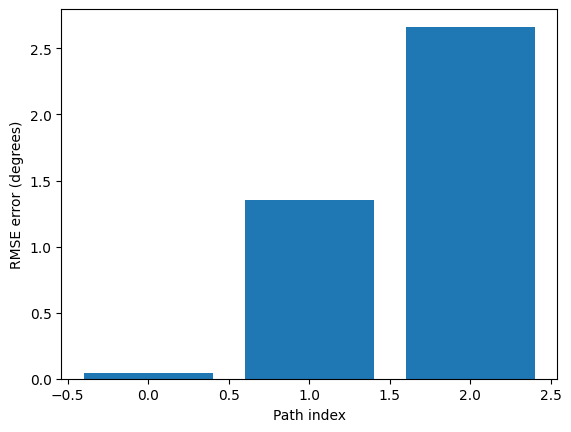

In [44]:
print(RMSE)
plt.bar(np.arange(0, 3, 1), RMSE[1, :])
plt.ylabel('RMSE error (degrees)')
plt.xlabel("Path index")